In [525]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from matplotlib.patches import Rectangle
from ipywidgets import VBox, HBox, FloatSlider, Output, FloatLogSlider, Button, Checkbox, Layout, IntSlider
import ipywidgets as widgets
from IPython.display import display, clear_output, Audio
from scipy.interpolate import RegularGridInterpolator
import json
from scipy.special import jv
import sys

build_dir = "cppSimulation/build"
if build_dir not in sys.path:
    sys.path.insert(0, build_dir)

import propagationmod
import resamplemod

%matplotlib inline

sr= 48000
c = 344

In [526]:
todeg = 180 / np.pi
def computeZ(mp, k):
    return np.array([np.exp(np.dot(k, mp[i])*1j) for i in range(len(mp))])

def plot_mesh_polar(ax, plot_points, z):
    aziv, zeniv = plot_points
    c = ax.pcolormesh(aziv, zeniv * todeg, np.abs(z), shading='gouraud', cmap='viridis')
    ax.set_ylim([0, 90 + 1e-5])
    plt.colorbar(c, ax=ax)

def polar_to_look_direction(aziv, zeniv):
    return np.stack((
        np.cos(aziv) * np.sin(zeniv),
        np.sin(aziv) * np.sin(zeniv),
        np.cos(zeniv)), axis=-1)

def create_look_directions(n, fov):

    fov += 1e-5
    x = np.linspace(-fov, fov, n)
    y = np.linspace(-fov, fov, n)

    xv, yv = np.meshgrid(x, y)

    # circle the square
    # ratio = np.maximum(np.abs(xv), np.abs(yv)) / (np.sqrt(xv*xv + yv*yv) + 1e-18)
    # xv *= ratio
    # yv *= ratio
    
    xv = np.reshape(xv, -1)
    yv = np.reshape(yv, -1)
    aziv = np.atan2(yv, xv)
    zeniv = np.sqrt(xv*xv + yv*yv)

    unit_look_direction = polar_to_look_direction(aziv, zeniv)
    
    # xy = np.stack((xv, yv), axis = -1)

    return (unit_look_direction, aziv, zeniv, (x, y))

def create_distance_vectors(look_directions, microphone_positions):
    return look_directions @ microphone_positions

def create_steering_vectors(distance_vectors, k):
    return np.exp(1j * distance_vectors * k)

class ArrayState:
    positions = np.array([[0, 0, 0]])
    cropac = {}
    calibration = np.array([])
    def __init__(self, pos=np.array([[0, 0, 0]]), cropac={}):
        self.positions = pos
        self.cropac = cropac
        self.calibration = np.array([])

def load_array(path, calibrationPath):

    array = ArrayState()
    with open(path, "r", encoding="utf-8") as f:
        array.__dict__ = json.load(f)
    array.positions = np.stack((*np.array(array.positions).T, np.zeros(len(array.positions))))
    
    with open(calibrationPath, "r", encoding="utf-8") as f:
        array.calibration = np.array(json.load(f))

    array.positions[0] -= np.mean(array.positions[0])
    array.positions[1] -= np.mean(array.positions[1])
    
    return array

def default8():
    return load_array("default_array8_1.json", "default_array8_calibration_old.json")

def circle8():
    return load_array("circle_array8.json", "circle_array8_calibration.json")

In [527]:
# CroPaC for a planar circular array

def planar_directions(directions):
    return np.atan2(directions[:,1], directions[:,0])

def zeni_directions(directions):
    return np.atan2(np.sqrt(directions[:,0]**2 + directions[:,1]**2), directions[:,2])

def polar_to_unitdir(aziv, zeniv):
    unit_look_direction = np.stack((
        np.cos(aziv) * np.sin(zeniv),
        np.sin(aziv) * np.sin(zeniv),
        np.cos(zeniv)), axis=-1)
    return unit_look_direction

def diffuse_noise_covariance(mic_array, k):
    n = mic_array.shape[1]
    dist = np.zeros((n, n), dtype=np.complex128)
    for i in range(n):
        for j in range(n):
            d = mic_array[:,i] - mic_array[:,j]
            dist[i,j] = np.sqrt(np.sum(d*d))
    return np.sinc(k * dist)

def create_primary_weights(look_direction, look_vector, mic_array, k):

    mic = planar_directions(mic_array.T)
    dir = planar_directions(look_direction[None,:])
    relative_angles = dir[0] - mic

    m = mic_array.shape[1]
    r = np.sqrt(np.sum(mic_array[:,0] * mic_array[:,0]))

    o1 = 1

    dj_zeros = [0, 1.8411837813, 3.0542369282, 4.2011889412]

    w1_zeni = np.arcsin(min(1, dj_zeros[o1] / (k * r)))
    look_zeni = zeni_directions(look_direction[None,:])[0]

    zeni_steer = min(1, k * r / dj_zeros[o1])**2
    zeni_steer1 = k * r * (np.sin(w1_zeni) - np.sin(look_zeni)) * zeni_steer
    kr1n = min(k * r + zeni_steer1, dj_zeros[o1])
    w1 = np.cos(o1 * relative_angles) * (1j**o1) / (jv(o1, kr1n)) / m

    dv0 = create_distance_vectors(polar_to_unitdir(dir, np.array([np.pi/2])), mic_array)

    sv1 = create_steering_vectors(dv0, zeni_steer1 / r)

    correction1 = np.conj(sv1)

    w1 = w1 * correction1[0]

    das_w1 = look_vector / m * 2

    for i in range(8):
        if i&1:
            das_w1[i] = 0

    j0_zero = 2.4048
    mlw = np.arcsin(min(1, j0_zero / (k*r)))

    bstart = 45 / todeg
    bend = 30 / todeg
    mlw = min(bstart, max(mlw, bend))

    blend = (bstart - mlw) / (bstart - bend)

    w1 = w1 * (1 - blend) + das_w1 * blend

    return w1

def create_optimal_secondary_weights(w1, look_vector, constraints):
    
    N = w1.shape[0]
    nsdim = N - len(constraints)
    assert nsdim > 0

    constraints = [i / np.linalg.norm(i) for i in constraints]
    for i in range(N-nsdim):
        for j in range(0, i):
            constraints[i] -= (constraints[i] @ np.conj(constraints[j])) * constraints[j]
            constraints[i] /= np.linalg.norm(constraints[i])

    O = []
    for i in range(nsdim):
        basisv = np.random.randn(N).astype(np.complex128)
        basisv /= np.linalg.norm(basisv)
        for v in constraints:
            basisv -= (basisv @ np.conj(v)) * v
            basisv /= np.linalg.norm(basisv)
        constraints.append(basisv)
        O.append(basisv)

    O = np.array(O).T

    # w2 = O @ np.linalg.inv(np.conj(O).T @ O) @ np.conj(O).T @ look_vector
    w2 = O @ np.linalg.pinv(O) @ look_vector
    w2 = w2 / (np.conj(w2) @ look_vector)

    return w2 

def cropac_beampattern(w1, w2, steering_vectors):

    m = steering_vectors.shape[1]
    z1 = steering_vectors @ np.conj(w1)
    z2 = steering_vectors @ np.conj(w2)

    g = np.maximum(0, np.real(np.conj(z1) * z2))

    return z1, z2, g

def mvdr_weights(R, steering_vectors, dial = 1.5):
    loading = dial * np.trace(R).real / R.shape[0]
    w = steering_vectors @ np.linalg.inv(R + loading * np.eye(R.shape[0]))
    norm = np.sum(np.conj(steering_vectors) * w, axis=-1)
    w /= norm[..., None]
    return w

def rms_normalize(x):
    return x / (np.sqrt(np.mean(x * x)) + 1e-18)

def create_diffuse_noise(n, micpos, sr):
    m = micpos.shape[1]
    vel = np.zeros((3, n), dtype=np.float32)
    pos = np.random.randn(3, n) * 10
    pos /= np.linalg.norm(pos, axis=0)
    noise = propagationmod.simulate_audio_propagation(sr, micpos, pos, vel, np.random.randn(n))
    pos = np.flip(pos)
    noise += propagationmod.simulate_audio_propagation(sr, micpos, pos, vel, np.random.randn(n))
    noise += np.roll(noise, noise.shape[1]//8)
    noise += np.roll(noise, noise.shape[1]//4)
    noise += np.roll(noise, noise.shape[1]//2)
    noise = rms_normalize(noise)
    return noise

In [528]:
def plot_mesh_polar(ax, plot_points, z):
    aziv, zeniv = plot_points
    c = ax.pcolormesh(aziv, zeniv * todeg, np.abs(z), shading='gouraud', cmap='viridis')
    ax.set_ylim([0, 90 + 1e-5])
    plt.colorbar(c, ax=ax)

def plot_mesh_planar(ax, plot_points, z):
    xv, yv = plot_points
    c = ax.pcolormesh(xv, yv, np.abs(z), shading='gouraud', cmap='viridis')
    plt.colorbar(c, ax=ax)

def plot_scene(target_direction, noise_directions):
    # Ensure inputs are 2D arrays with shape (N, 3)
    target = np.atleast_2d(target_direction)
    noise = np.atleast_2d(noise_directions)

    if target.shape[1] != 3:
        raise ValueError("target_direction must have shape (3,) or (N, 3)")
    if noise.shape[1] != 3:
        raise ValueError("noise_directions must have shape (M, 3)")

    fig = plt.figure(figsize=(fig_width, fig_width*0.4))
    ax = fig.add_subplot(111, projection='3d')

    ax.scatter(0, 0, 0,
            s=80, c='tab:red', marker='o', label='Origin')

    # Plot noise directions
    ax.scatter(noise[:, 0], noise[:, 1], noise[:, 2],
            s=20, c='tab:blue', alpha=0.7, label='Noise Direction')

    # Plot target direction(s)
    ax.scatter(target[:, 0], target[:, 1], target[:, 2],
            s=100, c='tab:red', marker='x', label='Target Direction')

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.legend()
    ax.grid(True)
    ax.axis('equal')
    # ax.set_box_aspect((1, 1, 1))  # Equal aspect ratio

    plt.show()

In [529]:
def design_bump_filt(sr, mid, wid, N=2**11):
    fmin = mid-wid
    fmax = mid+wid
    mi = N / sr * fmin
    ma = N / sr * fmax
    filt = np.zeros(N//2+1)
    for i in range(0, N//2+1):
        f = sr / N * i
        if mi <= i+1 and i <= ma:
            filt[i] = 0.5 * np.cos(((mid - f) / wid) * np.pi) + 0.5
    return filt

def fftwin_filt(x, filt):
    N = 2 * len(filt) - 2
    imp = np.fft.irfft(filt)
    imp = np.roll(imp, N//2)
    imp *= np.hanning(N)
    y = scipy.signal.convolve(x, imp)
    return y[N//2: -N//2+1]

def spatial_propagation(x, dirs, mp, N):
    r = np.sqrt(np.sum(mp[:,0] * mp[:,0]))
    delay = (r + create_distance_vectors(dirs, mp)) / c * sr
    DMAX = int(np.ceil(r / c * sr))
    m = mp.shape[1]
    d = dirs.shape[0]
    y = np.zeros((m, x.shape[1]))
    for i in range(m):
        for j in range(d):
            impc = delay[j,i] + N//2
            imp = np.zeros(2 * DMAX + N)
            for dd in range(2 * DMAX + N):
                dist = np.abs(dd - impc)
                if dist < N//2:
                    imp[dd] = np.sinc(dist) * (0.5 * np.cos(dist / N * 2 * np.pi) + 0.5) ** 2
            yy = scipy.signal.convolve(x[j], imp)
            y[i] += yy[N//2+DMAX: -N//2-DMAX+1]
    return y
    

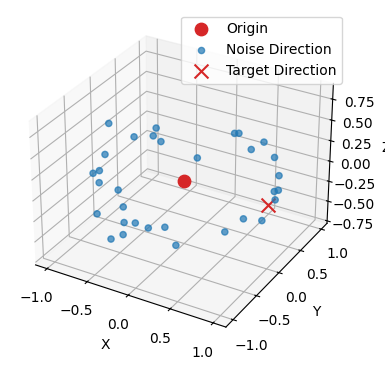

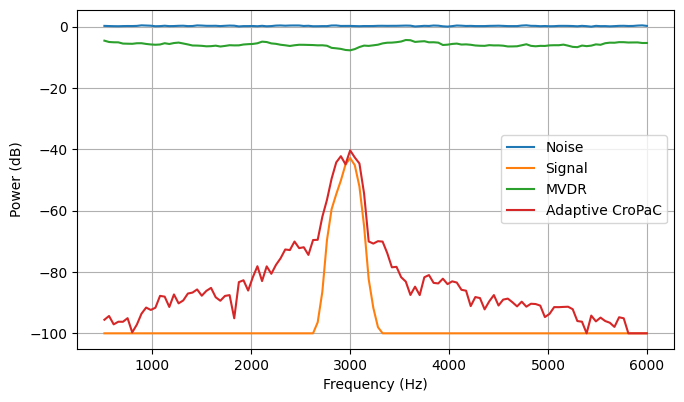

In [614]:
fig_width = 11

N = 2**10
BLOCK = 64 * N
f = np.fft.fftfreq(N, 1 / sr)
validi = (f >= 500) & (f <= 6000)
valids = np.where(validi == True)[0]
vaf = np.count_nonzero(validi)
seed = 12

array = circle8()
mp = array.positions
m = mp.shape[1]

kr = 2 * np.pi * f / c

gap = 0.1
target_direction = polar_to_look_direction(0, np.pi/2)
noise_sources = 4 * m

np.random.seed(seed)
noise_directions = polar_to_look_direction(
    np.linspace(gap, np.pi*2-gap, noise_sources) + np.random.randn(noise_sources) * 0.2,
    np.pi/2 + np.random.randn(noise_sources) * 0.2)

def generate_signal_block():
    target_signal = np.random.randn(BLOCK)
    # target_signal = rms_normalize(target_signal)
    filt = design_bump_filt(sr, 3000, 100, N)
    target_signal = fftwin_filt(target_signal, filt)
    target_signal = target_signal.reshape((1, BLOCK))
    noise_signal = np.random.randn(noise_sources*BLOCK).reshape((noise_sources, BLOCK))
    target_signal = spatial_propagation(target_signal, target_direction[None,:], mp, N)
    noise_signal = spatial_propagation(noise_signal, noise_directions, mp, N) / np.sqrt(noise_sources)

    # noise_signal = create_diffuse_noise(BLOCK, mp, sr)
    # target_signal = propagationmod.static_audio_propagation(sr, mp, np.array([10, 0, 0]), target_signal) 

    return target_signal, noise_signal


time = 10
samples = int(np.ceil(time / (N / sr)))
opt_spec = np.zeros(N, dtype=np.complex128)
sn_spec = np.zeros(N, dtype=np.complex128)
s_spec = np.zeros(N, dtype=np.complex128)
n_spec = np.zeros(N, dtype=np.complex128)
mvdr_spec = np.zeros(N, dtype=np.complex128)

Sn = np.zeros((vaf, m, m), dtype=np.complex128)

np.random.seed(seed)
scounter = 0
while scounter < samples:
    
    _, nn = generate_signal_block()

    for i in range(5*N, BLOCK-5*N, N):

        snapn = np.fft.rfft((nn[:,i:i+N]) * np.hanning(N)[None,:])
        snapn = snapn[:,validi[:N//2+1]]
        n_spec[validi] += np.sum(np.abs(snapn)**2, axis=0)/np.sqrt(m)/N

        Sn += snapn.T[:,:,None] @ np.conj(snapn.T[:,None,:])

        scounter += 1
        if scounter >= samples:
            break

Sn /= samples

w1 = np.zeros((N, m), dtype=np.complex128)
w2 = np.zeros((N, m), dtype=np.complex128)
w_mvdr = np.zeros((N, m), dtype=np.complex128)

for i in valids:

    k = kr[i]

    target_steer = create_steering_vectors(create_distance_vectors(target_direction[None,:], mp), k)[0]

    # noise_steer = create_steering_vectors(create_distance_vectors(noise_directions, mp), k)
    # Sn = np.zeros((m, m), dtype=np.complex128)
    # for nv in noise_steer:
    #     Sn += nv[:,None] @ np.conj(nv[None,:])
    # Sn = np.eye(m)
    # Sd = diffuse_noise_covariance(mp, k)

    S = Sn[i-valids[0]]

    ww1 = create_primary_weights(target_direction, target_steer, mp, k)
    constraints = [S @ ww1]
    ww2 = create_optimal_secondary_weights(ww1, target_steer, constraints)
    w1[i,:] = ww1
    w2[i,:] = ww2

    w_mvdr[i,:] = mvdr_weights(S, target_steer, 0.1)

w1 = w1[validi]
w2 = w2[validi]
w_mvdr = w_mvdr[validi]

np.random.seed(seed)
scounter = 0
while scounter < samples:
    ss, nn = generate_signal_block()
    ss *= 1e-2

    for i in range(5*N, BLOCK-5*N, N):
        
        snap = np.fft.rfft((ss[:,i:i+N] + nn[:,i:i+N]) * np.hanning(N)[None,:])
        snap = snap[:,valids]

        z1 = np.sum(np.conj(w1).T * snap, axis=0)
        z2 = np.sum(np.conj(w2).T * snap, axis=0)
        opt_spec[validi] += np.conj(z1) * z2 / N * 2
        # sn_spec[validi] += np.sum(np.abs(snap)**2, axis=0)/np.sqrt(m)/N

        snaps = np.fft.rfft((ss[:,i:i+N]) * np.hanning(N)[None,:])
        snaps = snaps[:,valids]
        s_spec[validi] += np.sum(np.abs(snaps)**2, axis=0)/np.sqrt(m)/N

        mvdr_spec[validi] += np.abs(np.sum(np.conj(w_mvdr).T * snap, axis=0))**2/np.sqrt(N)/m

        scounter += 1
        if scounter >= samples:
            break

plot_scene(target_direction, noise_directions)

def db_scale(x, amin=1e-10):
    return 10.0 * np.log10(np.maximum(np.abs(x), amin))

fig = plt.figure(figsize=(fig_width*0.7, fig_width*0.4))
ax = fig.add_subplot(111)
# plt.plot(f[validi], db_scale(sn_spec[validi] / samples))
ax.plot(f[validi], db_scale(n_spec[validi] / samples), label="Noise")
ax.plot(f[validi], db_scale(s_spec[validi] / samples), label="Signal")
ax.plot(f[validi], db_scale(mvdr_spec[validi] / samples), label="MVDR")
ax.plot(f[validi], db_scale(opt_spec[validi] / samples), label="Adaptive CroPaC")
ax.grid()

ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("Power (dB)")

plt.legend()
plt.show()

# plt.figure()
# plt.plot(f[validi], np.sum(np.abs(w1)**2, axis=1))
# plt.plot(f[validi], np.sum(np.abs(w2)**2, axis=1))